<a href="https://colab.research.google.com/github/api-sage/recommender_systems/blob/main/proj2/pafolabi_FoodRecSys.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Food Recommender System Analysis

###Name: Paul Afolabi
###AndrewID: pafolabi

### Dataset: Food Recommendation System
This dataset contains food items, user interactions, ratings, and features suitable for building a food recommendation system.

You can access the dataset on Kaggle here: [Food Recommendation System Dataset](https://www.kaggle.com/datasets/schemersays/food-recommendation-system)

In [50]:
#Importation of libraries
import os
import glob
import pandas as pd
import kagglehub
import kagglehub
from kagglehub import KaggleDatasetAdapter


In [51]:
# Set the path to the specific file you'd like to load
file_path = "1662574418893344.csv"

# Load the latest version using dataset_load
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "schemersays/food-recommendation-system",
  file_path
)

print("First 5 records:")
display(df.head())

Using Colab cache for faster access to the 'food-recommendation-system' dataset.
First 5 records:


,Food_ID,Name,C_Type,Veg_Non,Describe
0,1,summer squash salad,Healthy Food,veg,"white balsamic vinegar, lemon juice, lemon rin..."
1,2,chicken minced salad,Healthy Food,non-veg,"olive oil, chicken mince, garlic (minced), oni..."
2,3,sweet chilli almonds,Snack,veg,"almonds whole, egg white, curry leaves, salt, ..."
3,4,tricolour salad,Healthy Food,veg,"vinegar, honey/sugar, soy sauce, salt, garlic ..."
4,5,christmas cake,Dessert,veg,"christmas dry fruits (pre-soaked), orange zest..."


In [52]:
# Get the path to the downloaded dataset directory
path = kagglehub.dataset_download("schemersays/food-recommendation-system")
print(f"Dataset downloaded to: {path}")

# List all files in the directory to find user ratings or interactions
files = glob.glob(os.path.join(path, "*"))
print("\nAvailable files in this dataset:")
for f in files:
    print(f"- {os.path.basename(f)}")

Using Colab cache for faster access to the 'food-recommendation-system' dataset.
Dataset downloaded to: /kaggle/input/food-recommendation-system

Available files in this dataset:
- 1662574418893344.csv
- ratings.csv


In [53]:
# Let's find and load other CSV files found in the directory
csv_files = [os.path.basename(f) for f in files if f.endswith('.csv')]

for csv_file in csv_files:
    if csv_file != "1662574418893344.csv":
        print(f"\nLoading {csv_file}...")
        # Load using kagglehub to keep configuration consistent
        temp_df = kagglehub.dataset_load(
            kagglehub.KaggleDatasetAdapter.PANDAS,
            "schemersays/food-recommendation-system",
            csv_file
        )
        print(f"Shape of {csv_file}: {temp_df.shape}")
        print("Columns:", temp_df.columns.tolist())
        display(temp_df.head(2))

        # Dynamically assign to descriptive variables if they represent ratings
        # Using .str.lower() to check elements correctly
        if any(col in temp_df.columns.str.lower() for col in ['rating', 'user_id', 'food_id']):
            ratings_df = temp_df
            print("-> Successfully loaded and assigned to 'ratings_df'")


Loading ratings.csv...
Using Colab cache for faster access to the 'food-recommendation-system' dataset.
Shape of ratings.csv: (512, 3)
Columns: ['User_ID', 'Food_ID', 'Rating']


,User_ID,Food_ID,Rating
0,1.0,88.0,4.0
1,1.0,46.0,3.0


-> Successfully loaded and assigned to 'ratings_df'


## 2. Data Collection
### Step 1: Choose a Recommendation Domain
Select one topic/source for your recommender-system dataset.

I chose food recommendation. People face the same question every day, which is what to eat, and a good recommender can save them time and help them find dishes they would enjoy. The users are people who rate dishes, the items are food dishes, and the interaction is a rating from each user on a dish.

### Step 2: Collect Meaningful Data
Your dataset must contain enough relevant information to support meaningful analysis. Consider: What are the users? What are the items? What interactions exist between users and items? Are there ratings, reviews, comments, prices, categories, descriptions, or other attributes? Is the dataset sufficiently large and diverse to reveal useful patterns?

I got the data from Kaggle (Food Recommendation System dataset, from 2022) through the `kagglehub` library, so the code below pulls it straight from the source. It is a public dataset, so I did not scrape anything myself. The cell below puts the data into two clear tables: one for the food items and one for the user ratings.

In [54]:
# Put the loaded files into clear names: one table for foods, one for ratings
food_df = None
for name in csv_files + ["1662574418893344.csv"]:
    t = df if name == "1662574418893344.csv" else kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS, "schemersays/food-recommendation-system", name)
    cols = [c.lower() for c in t.columns]
    if "rating" in cols:
        ratings_df = t.copy()
    elif "name" in cols:
        food_df = t.copy()

# Use simple column names so the rest of the code is easy to read
ratings_df.columns = [c.strip() for c in ratings_df.columns]
food_df.columns = [c.strip() for c in food_df.columns]
print("Food table:", food_df.shape)
print("Ratings table:", ratings_df.shape)
print("Food columns:", food_df.columns.tolist())
print("Ratings columns:", ratings_df.columns.tolist())

Using Colab cache for faster access to the 'food-recommendation-system' dataset.
Food table: (400, 5)
Ratings table: (512, 3)
Food columns: ['Food_ID', 'Name', 'C_Type', 'Veg_Non', 'Describe']
Ratings columns: ['User_ID', 'Food_ID', 'Rating']


The ratings table links users to foods, so it is the main interaction data. The food table gives extra details about each dish, such as its name, cuisine type, veg or non-veg label and a short description. Having both means I can look at ratings and also at item content, which matters for the choice of recommender technique later.

## 3. Data Analysis
### A. Dataset Definition and Description
Clearly describe your dataset, including: data source, number of users, number of items, number of records/interactions, features/attributes, rating/review/comment information, and other relevant characteristics. Explain what each important feature represents.

In [55]:
# Column names for users, items and ratings (found from the data so the code does not break)
user_col = [c for c in ratings_df.columns if "user" in c.lower()][0]
item_col = [c for c in ratings_df.columns if "food" in c.lower() or "item" in c.lower()][0]
rate_col = [c for c in ratings_df.columns if "rating" in c.lower()][0]

n_users = ratings_df[user_col].nunique()
n_items_rated = ratings_df[item_col].nunique()
n_items_total = food_df[item_col].nunique() if item_col in food_df.columns else len(food_df)
n_ratings = len(ratings_df)

print("Data source: Kaggle, schemersays/food-recommendation-system (2022)")
print("Number of users:", n_users)
print("Number of food items in the food table:", n_items_total)
print("Number of food items that have at least one rating:", n_items_rated)
print("Number of ratings (interactions):", n_ratings)
print("Rating scale: from", ratings_df[rate_col].min(), "to", ratings_df[rate_col].max())
print()
print("Ratings data types:")
print(ratings_df.dtypes)
print()
print("Food data types:")
print(food_df.dtypes)

Data source: Kaggle, schemersays/food-recommendation-system (2022)
Number of users: 100
Number of food items in the food table: 400
Number of food items that have at least one rating: 309
Number of ratings (interactions): 512
Rating scale: from 1.0 to 10.0

Ratings data types:
User_ID    float64
Food_ID    float64
Rating     float64
dtype: object

Food data types:
Food_ID      int64
Name        object
C_Type      object
Veg_Non     object
Describe    object
dtype: object


Here is what the important features mean, as I understand them from the data:

- **User_ID**: a number that identifies the person who gave the rating.
- **Food_ID**: a number that identifies a dish. It links the ratings table to the food table.
- **Rating**: the score the user gave the dish. A higher score means the user liked it more.
- **Name**: the name of the dish.
- **C_Type**: the cuisine or course type of the dish (for example Indian, Chinese or Healthy Food).
- **Veg_Non**: tells me if the dish is vegetarian or non-vegetarian.
- **Describe**: a short text with the ingredients or a description of the dish.

There are no written reviews or comments in this data. The only user feedback is the numeric rating. The dataset has both ratings and item content, so I can use it to talk about collaborative and content-based methods.

### B. Exploratory Data Analysis
Explore the structure and characteristics of the dataset. Where applicable, determine: total number of ratings/interactions, number of ratings/interactions per user, number of ratings/interactions per item, number of comments/reviews, item descriptions or categories, rating distributions, dataset sparsity, missing or unusual values, and other characteristics relevant to your recommendation problem.

#### B1. Total number of ratings and number of ratings per user

In [56]:
print("Total number of ratings:", n_ratings)
print("Number of comments/reviews: none in this dataset, only numeric ratings")

ratings_per_user = ratings_df.groupby(user_col)[rate_col].count()
print("\nRatings per user:")
print(ratings_per_user.describe())
print("\nUsers with only 1 rating:", (ratings_per_user == 1).sum())

Total number of ratings: 512
Number of comments/reviews: none in this dataset, only numeric ratings

Ratings per user:
count    100.000000
mean       5.110000
std        2.352282
min        1.000000
25%        3.000000
50%        5.000000
75%        7.000000
max       11.000000
Name: Rating, dtype: float64

Users with only 1 rating: 1


#### B2. Number of ratings per item

In [57]:
ratings_per_item = ratings_df.groupby(item_col)[rate_col].count()
print("Ratings per item (only items that were rated):")
print(ratings_per_item.describe())

unrated = n_items_total - n_items_rated
print("\nFood items with no rating at all:", unrated)
print("Items with only 1 rating:", (ratings_per_item == 1).sum())

Ratings per item (only items that were rated):
count    309.000000
mean       1.653722
std        1.107748
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        7.000000
Name: Rating, dtype: float64

Food items with no rating at all: 91
Items with only 1 rating: 199


#### B3. Item descriptions and categories

In [58]:
for col in food_df.columns:
    if food_df[col].dtype == object and food_df[col].nunique() < 30:
        print(col, "values and counts:")
        print(food_df[col].value_counts())
        print()

desc_col = [c for c in food_df.columns if "desc" in c.lower()]
if desc_col:
    print("Example descriptions:")
    for d in food_df[desc_col[0]].dropna().head(3):
        print("-", d)

C_Type values and counts:
C_Type
Indian          88
Healthy Food    58
Dessert         53
Chinese         27
Italian         25
Snack           23
Thai            23
French          22
Mexican         21
Japanese        18
Beverage        11
Nepalese        11
Korean           9
Vietnames        9
 Korean          1
Spanish          1
Name: count, dtype: int64

Veg_Non values and counts:
Veg_Non
veg        238
non-veg    162
Name: count, dtype: int64

Example descriptions:
- white balsamic vinegar, lemon juice, lemon rind, red chillies, garlic cloves (crushed), olive oil, summer squash (zucchini), sea salt, black pepper, basil leaves
- olive oil, chicken mince, garlic (minced), onion, salt, black pepper, carrot, cabbage, green onions, sweet chilli sauce, peanut butter, ginger, soy sauce, fresh cilantro, red pepper flakes (crushed), tarts
- almonds whole, egg white, curry leaves, salt, sugar (fine grain), red chilli powder


#### B4. Rating distribution

In [59]:
print(ratings_df[rate_col].value_counts().sort_index())
print("\nMean rating:", round(ratings_df[rate_col].mean(), 2))
print("Median rating:", ratings_df[rate_col].median())
print("Standard deviation:", round(ratings_df[rate_col].std(), 2))

Rating
1.0     48
2.0     47
3.0     63
4.0     53
5.0     61
6.0     48
7.0     49
8.0     39
9.0     42
10.0    61
Name: count, dtype: int64

Mean rating: 5.44
Median rating: 5.0
Standard deviation: 2.87


#### B5. Dataset sparsity
Sparsity tells me how much of the user by item rating matrix is empty.

In [60]:
# Sparsity using the items that were rated, and using all items in the food table
sparsity_rated = 1 - n_ratings / (n_users * n_items_rated)
sparsity_all = 1 - n_ratings / (n_users * n_items_total)
print(f"Sparsity (rated items only): {sparsity_rated:.4f} ({sparsity_rated*100:.2f}%)")
print(f"Sparsity (all items in food table): {sparsity_all:.4f} ({sparsity_all*100:.2f}%)")
print(f"Average ratings per user: {n_ratings / n_users:.2f}")
print(f"Average ratings per item: {n_ratings / n_items_total:.2f}")

Sparsity (rated items only): 0.9834 (98.34%)
Sparsity (all items in food table): 0.9872 (98.72%)
Average ratings per user: 5.12
Average ratings per item: 1.28


#### B6. Missing and unusual values

In [61]:
print("Missing values in ratings table:")
print(ratings_df.isnull().sum())
print("\nMissing values in food table:")
print(food_df.isnull().sum())

print("\nDuplicate rows in ratings table:", ratings_df.duplicated().sum())
print("Users who rated the same food more than once:",
      ratings_df.duplicated(subset=[user_col, item_col]).sum())
print("Duplicate food names:", food_df[[c for c in food_df.columns if c.lower()=='name'][0]].duplicated().sum())

# Ratings that are outside the normal range or not whole numbers
print("Non-whole-number ratings:", (ratings_df[rate_col] % 1 != 0).sum())

# Ratings that point to a food that is not in the food table
if item_col in food_df.columns:
    print("Ratings for foods missing from the food table:",
          (~ratings_df[item_col].isin(food_df[item_col])).sum())

Missing values in ratings table:
User_ID    1
Food_ID    1
Rating     1
dtype: int64

Missing values in food table:
Food_ID     0
Name        0
C_Type      0
Veg_Non     0
Describe    0
dtype: int64

Duplicate rows in ratings table: 0
Users who rated the same food more than once: 3
Duplicate food names: 0
Non-whole-number ratings: 1
Ratings for foods missing from the food table: 1


#### B6b. Cleaning the data
The checks above show one ratings row with no values at all, three users who rated the same food twice, and a few messy category labels (for example " Korean" with a space and "Vietnames" with a missing letter). I fix these here so the rest of the analysis is correct. Because of this step, the counts printed below this cell will be a little smaller than the raw counts above (the empty row is gone and repeated ratings are averaged).

In [62]:
# 1. Drop the row with missing values and make the IDs whole numbers
ratings_df = ratings_df.dropna().copy()
ratings_df[[user_col, item_col]] = ratings_df[[user_col, item_col]].astype(int)

# 2. If a user rated the same food twice, keep the average of the two ratings
before = len(ratings_df)
ratings_df = ratings_df.groupby([user_col, item_col], as_index=False)[rate_col].mean()
print("Rows removed by merging repeated ratings:", before - len(ratings_df))

# 3. Fix messy category labels
food_df["C_Type"] = food_df["C_Type"].str.strip().replace({"Vietnames": "Vietnamese"})
print("Categories now:", food_df["C_Type"].nunique())

# 4. Recalculate the main numbers
n_users = ratings_df[user_col].nunique()
n_items_rated = ratings_df[item_col].nunique()
n_ratings = len(ratings_df)
ratings_per_user = ratings_df.groupby(user_col)[rate_col].count()
ratings_per_item = ratings_df.groupby(item_col)[rate_col].count()
user_mean = ratings_df.groupby(user_col)[rate_col].mean()
item_mean = ratings_df.groupby(item_col)[rate_col].mean()
sparsity_all = 1 - n_ratings / (n_users * n_items_total)
print(f"Clean data: {n_users} users, {n_items_rated} rated foods, {n_ratings} ratings")
print(f"Sparsity (all {n_items_total} foods): {sparsity_all*100:.2f}%")

Rows removed by merging repeated ratings: 3
Categories now: 15
Clean data: 100 users, 309 rated foods, 508 ratings
Sparsity (all 400 foods): 98.73%


#### B7. Other useful characteristics: how much do users disagree, and is there a cold start problem?

In [63]:
# Average rating per user and per item
user_mean = ratings_df.groupby(user_col)[rate_col].mean()
item_mean = ratings_df.groupby(item_col)[rate_col].mean()
print("User average rating, spread:")
print(user_mean.describe())
print("\nItem average rating, spread:")
print(item_mean.describe())

# Cold start: items and users with very few ratings
print("\nItems with 2 or fewer ratings:", (ratings_per_item <= 2).sum(), "of", n_items_total)
print("Users with 5 or fewer ratings:", (ratings_per_user <= 5).sum(), "of", n_users)

User average rating, spread:
count    100.000000
mean       5.425837
std        1.581222
min        2.000000
25%        4.321429
50%        5.196429
75%        6.411111
max       10.000000
Name: Rating, dtype: float64

Item average rating, spread:
count    309.000000
mean       5.503198
std        2.534203
min        1.000000
25%        4.000000
50%        5.333333
75%        7.000000
max       10.000000
Name: Rating, dtype: float64

Items with 2 or fewer ratings: 257 of 400
Users with 5 or fewer ratings: 58 of 100


I looked at the structure of the data first. The results above give me the number of users, items and ratings, how many ratings each user and each item has, how the ratings are spread, how sparse the matrix is, and whether anything is missing or odd. I use these numbers in the discussion section.

### C. Data Visualizations
Create meaningful visualizations that reveal patterns, relationships, or dynamics in your dataset. Each visualization should answer a question or reveal something meaningful about the data.

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
sns.set_style("whitegrid")

name_col = [c for c in food_df.columns if c.lower() == "name"][0]
# Join ratings with food details so I can plot by dish
merged = ratings_df.merge(food_df, on=item_col, how="left")

#### C1. How are the ratings spread? (Question: do users give mostly high scores, or is it balanced?)

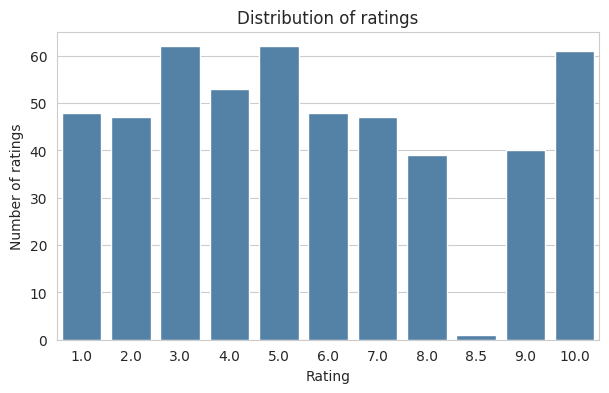

In [65]:
plt.figure(figsize=(7, 4))
sns.countplot(x=rate_col, data=ratings_df, color="steelblue")
plt.title("Distribution of ratings")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.show()

#### C2. How many ratings does each user give? (Question: do a few users give most of the ratings?)

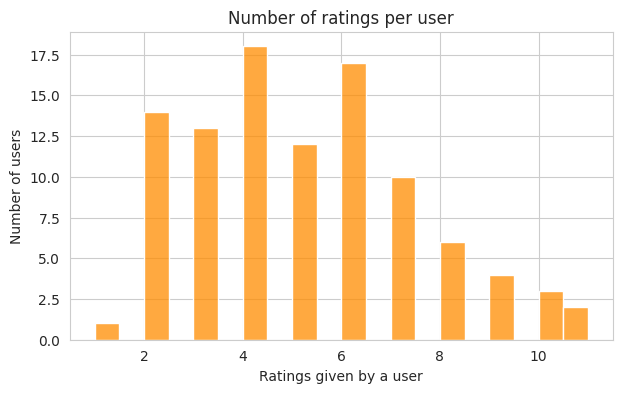

In [66]:
plt.figure(figsize=(7, 4))
sns.histplot(ratings_per_user, bins=20, color="darkorange")
plt.title("Number of ratings per user")
plt.xlabel("Ratings given by a user")
plt.ylabel("Number of users")
plt.show()

#### C3. How many ratings does each food get? (Question: are some foods much more popular than others?)

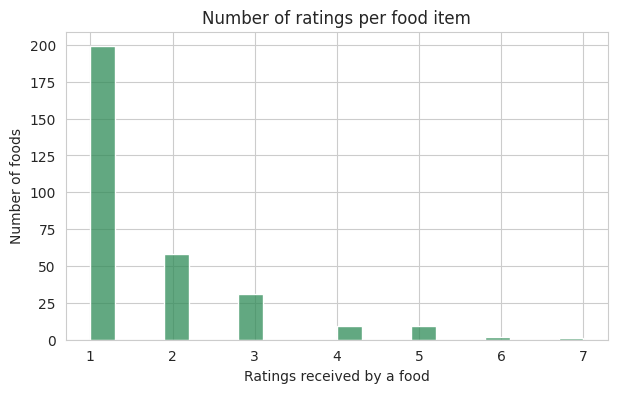

In [67]:
plt.figure(figsize=(7, 4))
sns.histplot(ratings_per_item, bins=20, color="seagreen")
plt.title("Number of ratings per food item")
plt.xlabel("Ratings received by a food")
plt.ylabel("Number of foods")
plt.show()

#### C4. Top 20 most active users

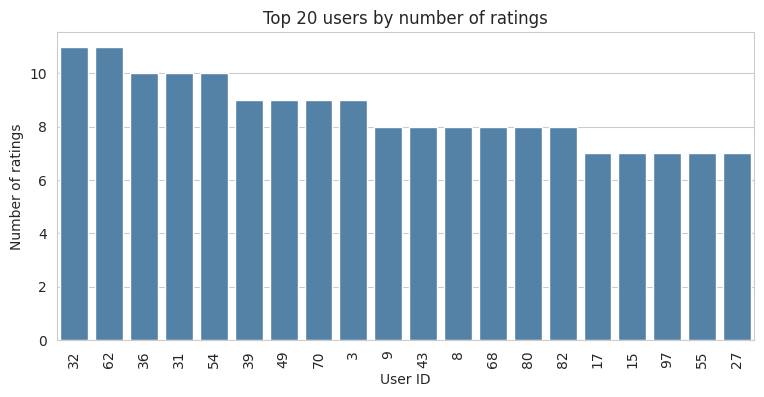

Share of all ratings from these 20 users: 33.7 %


In [68]:
top_users = ratings_per_user.sort_values(ascending=False).head(20)
plt.figure(figsize=(9, 4))
sns.barplot(x=top_users.index.astype(str), y=top_users.values, color="steelblue")
plt.title("Top 20 users by number of ratings")
plt.xlabel("User ID")
plt.ylabel("Number of ratings")
plt.xticks(rotation=90)
plt.show()

print("Share of all ratings from these 20 users:", round(top_users.sum() / n_ratings * 100, 1), "%")

#### C5. Top 20 most popular foods (most ratings)

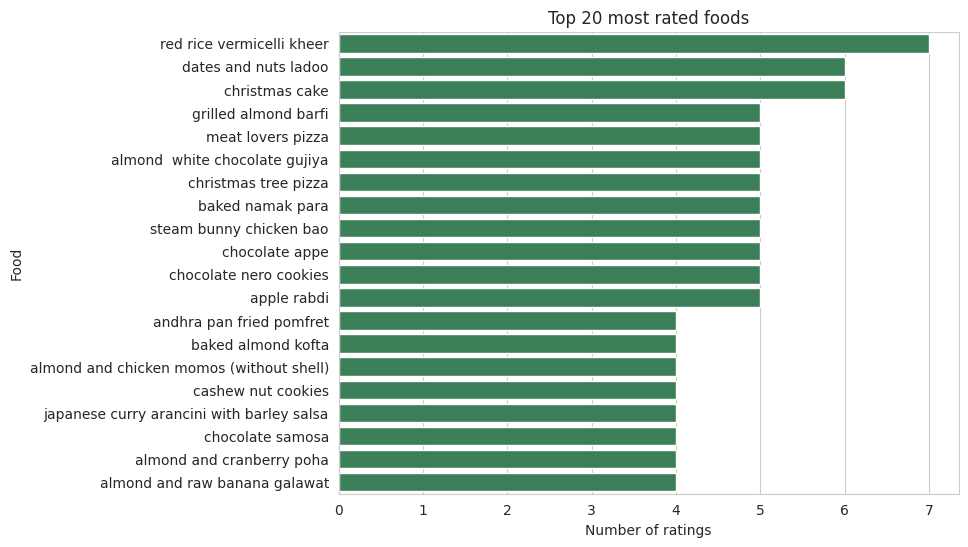

In [69]:
top_items = ratings_per_item.sort_values(ascending=False).head(20)
top_names = food_df.set_index(item_col).loc[top_items.index, name_col]
plt.figure(figsize=(8, 6))
sns.barplot(x=top_items.values, y=top_names.values, color="seagreen")
plt.title("Top 20 most rated foods")
plt.xlabel("Number of ratings")
plt.ylabel("Food")
plt.show()

#### C6. Item popularity vs. average rating (Question: are popular foods also the ones people like most?)

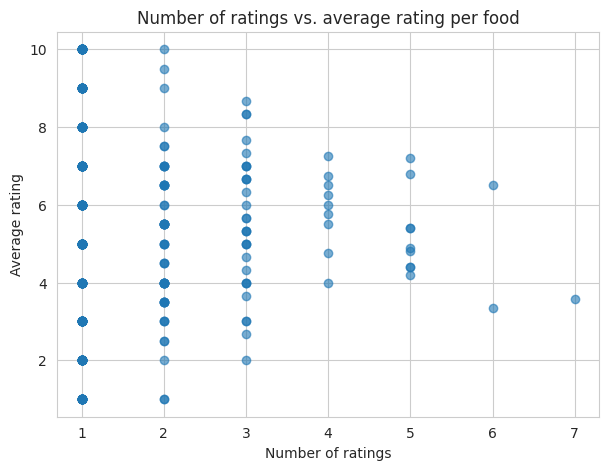

Correlation: -0.045


In [70]:
item_stats = pd.DataFrame({"n_ratings": ratings_per_item, "avg_rating": item_mean})
plt.figure(figsize=(7, 5))
plt.scatter(item_stats["n_ratings"], item_stats["avg_rating"], alpha=0.6)
plt.title("Number of ratings vs. average rating per food")
plt.xlabel("Number of ratings")
plt.ylabel("Average rating")
plt.show()
print("Correlation:", round(item_stats["n_ratings"].corr(item_stats["avg_rating"]), 3))

#### C7. Ratings by food category and veg or non-veg (Question: do some types of food get higher ratings?)

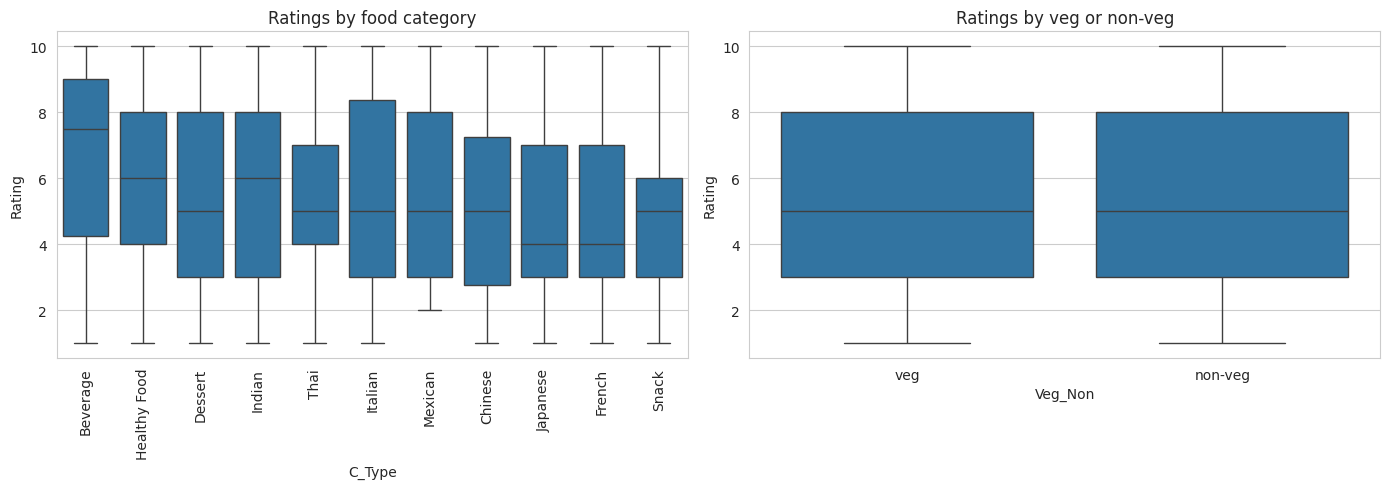

              count      mean
C_Type                       
Indian          112  5.553571
Dessert         102  5.568627
Healthy Food     73  5.602740
Snack            46  4.826087
Japanese         35  4.971429
Italian          34  5.514706
French           26  4.884615
Mexican          25  5.480000
Thai             21  5.523810
Chinese          20  5.150000
Beverage         14  6.571429
         count      mean
Veg_Non                 
non-veg    164  5.457317
veg        344  5.414244


In [71]:
cat_col = [c for c in food_df.columns if "type" in c.lower()][0]
veg_col = [c for c in food_df.columns if "veg" in c.lower()][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = merged.groupby(cat_col)[rate_col].mean().sort_values(ascending=False).index
sns.boxplot(x=cat_col, y=rate_col, data=merged, order=order, ax=axes[0])
axes[0].set_title("Ratings by food category")
axes[0].tick_params(axis="x", rotation=90)

sns.boxplot(x=veg_col, y=rate_col, data=merged, ax=axes[1])
axes[1].set_title("Ratings by veg or non-veg")
plt.tight_layout()
plt.show()

print(merged.groupby(cat_col)[rate_col].agg(["count", "mean"]).sort_values("count", ascending=False))
print(merged.groupby(veg_col)[rate_col].agg(["count", "mean"]))

#### C8. Do users rate in the same way? (Question: do some users always rate high and others low?)

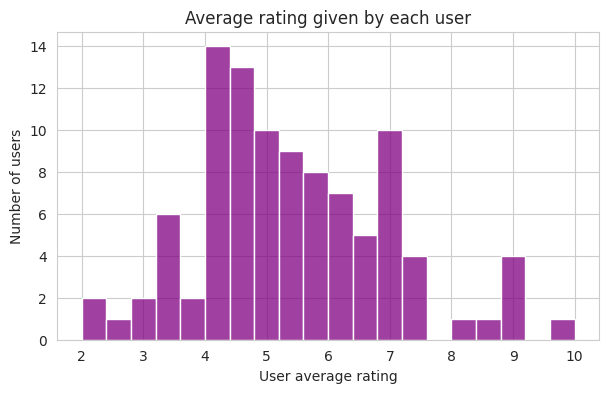

In [72]:
plt.figure(figsize=(7, 4))
sns.histplot(user_mean, bins=20, color="purple")
plt.title("Average rating given by each user")
plt.xlabel("User average rating")
plt.ylabel("Number of users")
plt.show()

#### C9. Where are the ratings in the user by item matrix? (Question: how empty is the matrix?)

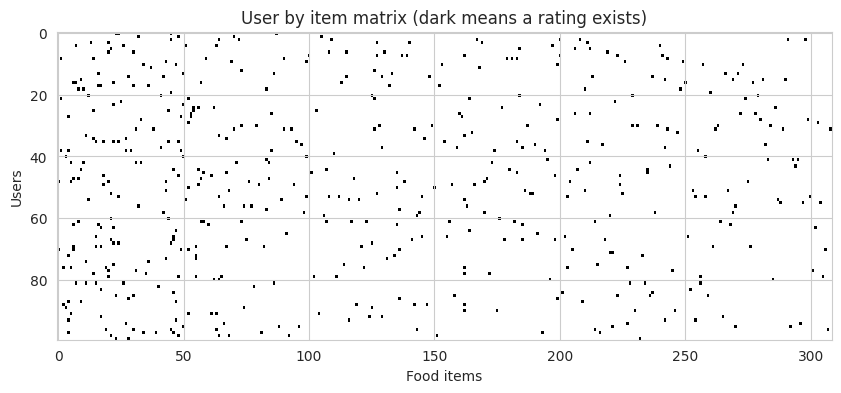

In [73]:
matrix = ratings_df.pivot_table(index=user_col, columns=item_col, values=rate_col)
plt.figure(figsize=(10, 4))
plt.imshow(matrix.notna().values, aspect="auto", cmap="Greys", interpolation="nearest")
plt.title("User by item matrix (dark means a rating exists)")
plt.xlabel("Food items")
plt.ylabel("Users")
plt.show()

#### C10. Is the rating pattern concentrated in a few foods? (Question: how strong is the long tail?)

Top 10% of foods (40 foods) get 30.9% of all ratings
Foods with no rating: 91 of 400


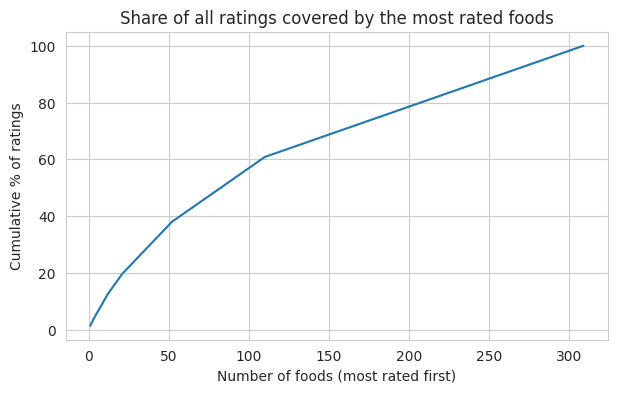

In [74]:
counts_sorted = ratings_per_item.sort_values(ascending=False)
top10_share = counts_sorted.head(int(0.1 * n_items_total)).sum() / n_ratings * 100
print(f"Top 10% of foods ({int(0.1 * n_items_total)} foods) get {top10_share:.1f}% of all ratings")
print(f"Foods with no rating: {n_items_total - n_items_rated} of {n_items_total}")

cum = counts_sorted.cumsum() / n_ratings * 100
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum) + 1), cum.values)
plt.title("Share of all ratings covered by the most rated foods")
plt.xlabel("Number of foods (most rated first)")
plt.ylabel("Cumulative % of ratings")
plt.show()

#### C11. Do users who rate more also rate differently? (Question: does activity change the average score?)

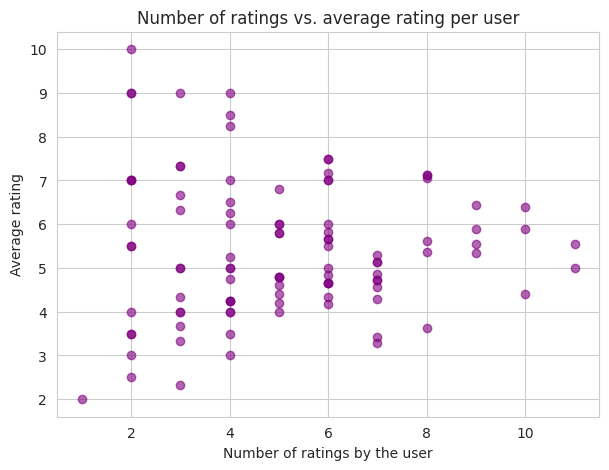

Correlation: 0.003


In [75]:
user_stats = pd.DataFrame({"n_ratings": ratings_per_user, "avg_rating": user_mean})
plt.figure(figsize=(7, 5))
plt.scatter(user_stats["n_ratings"], user_stats["avg_rating"], alpha=0.6, color="purple")
plt.title("Number of ratings vs. average rating per user")
plt.xlabel("Number of ratings by the user")
plt.ylabel("Average rating")
plt.show()
print("Correlation:", round(user_stats["n_ratings"].corr(user_stats["avg_rating"]), 3))

## 4. Discussion
Interpret your analysis and explain what you learned from the dataset.

*Note: the numbers below come from the outputs above. After the cleaning step in B6b, a few counts move by one or two, so re-run the notebook and check them before copying them into the paper.*

#### What questions can this dataset answer?
- Which foods get the most ratings, and which get the best scores?
- Do users agree on what is good, or does each person have their own taste?
- Does the type of food (cuisine or veg and non-veg) change the rating?
- Can we guess a rating a user has not given yet? This is the main job of a recommender system.

#### What insights did I get, and what do the visualizations show?
- **Ratings are spread out, not bunched at the top.** The scale is 1 to 10 and the mean is 5.44 with a standard deviation of 2.87. Scores of 3, 5 and 10 are the most common. This is unusual, because most real rating data leans high. It looks like the ratings may be simulated or collected in a very mixed way, so I treat the scores with some care (C1).
- **Activity is uneven, but not extreme.** Users gave about 5 ratings each on average (between 1 and 11). The top 20 users gave 33.8% of all ratings, which is more than their 20% share of users (C2, C4).
- **Most foods have almost no ratings.** A food gets 1.65 ratings on average, and the most rated food has only 7. 91 of the 400 foods have no rating and 199 have just one. A small set of foods gets more attention than the rest, but no food is a real hit (C3, C5, C10).
- **Popular does not mean liked.** The correlation between the number of ratings and the average rating is about -0.04, so it is basically zero. A popularity list would not tell me which foods people enjoy (C6).
- **Food type barely changes the score.** Veg and non-veg foods average 5.43 and 5.46. Most cuisines sit between 5 and 5.6. Snacks (4.83) are lower and beverages (6.57) are higher, but beverages only have 14 ratings, so I would not trust that gap (C7).
- **Users rate in their own way.** The average score per user goes from 2 to 10 (standard deviation 1.58). Some users are strict and some are generous, so a model should adjust for each user's habit, not only look at the raw score (C8).
- **The rating matrix is almost empty.** Sparsity is about 98.7% when I use all 400 foods (C9).

#### Unusual trends and critical issues
- **Sparsity and cold start.** 256 of 400 foods have 2 or fewer ratings, and 58 of 100 users have 5 or fewer. For most foods, there is not enough data to say if they are good or bad.
- **Data quality problems.** The ratings file had one empty row, three repeated user and food pairs and messy category labels. I fixed these in B6b.
- **Weak signal in the scores.** Food type and popularity explain almost nothing about the ratings. This means a simple rule will not predict a rating well, and the signal is mostly in who the user is.
- **No written reviews.** I only have numbers, so I cannot learn why someone liked a dish.

#### Limitations
- The dataset is not robust enough (100 users, 400 foods, about 510 ratings), so a model built on it may not hold up on a bigger group of users.
- I do not know how the ratings were collected. The flat spread of scores suggests they may be partly made up, so there could be bias.
- There is no time stamp, so I cannot study how tastes change or split the data by time.
- There is no information on the users (age, region, diet), so I cannot personalize beyond their ratings.
- Item content is limited to the category, the veg label and a short ingredient list.
- I did not build or test a model in this analysis. The technique choices below are based on what the data looks like.

#### Which recommender-system techniques fit this data, and why?
- **Popularity-based recommendation**: a simple baseline and a fallback for new users. Because popularity and rating are not related here, I expect it to be weak, but it is still a good thing to compare the other methods against.
- **User-based and item-based collaborative filtering**: these use the rating matrix to find similar users or foods. With only about 1.65 ratings per food and 98.7% sparsity, two foods rarely share a rater, so the similarity scores will be weak. I expect these to struggle.
- **Matrix factorization (such as SVD)**: it learns hidden taste factors and copes with sparse data better than neighbour methods. I would add a user bias term, because users differ so much in how strict they are (C8).
- **Content-based filtering**: the food table has categories, a veg label and ingredient text. I can turn the ingredients into TF-IDF vectors and recommend foods close to what a user rated highly. This also helps with the 91 foods that have no ratings.
- **Hybrid approach**: mixing collaborative and content-based methods is the most sensible choice. The ratings are too sparse to work alone, and the content fills the gap.

**Overall:** the data is sparse, uneven and noisy, and food type does not explain the ratings. So I would build a content-based model on the ingredient text, add matrix factorization with user bias, and use popularity as the baseline. I would judge them with RMSE and precision at K on a held-out set of ratings.

## 5. References
1. Schemersays, "Food Recommendation System," Kaggle, 2022. [Online]. Available: https://www.kaggle.com/datasets/schemersays/food-recommendation-system
2. F. Ricci, L. Rokach and B. Shapira, Eds., *Recommender Systems Handbook*, 3rd ed. New York, NY, USA: Springer, 2022.
3. Y. Koren, R. Bell and C. Volinsky, "Matrix factorization techniques for recommender systems," *Computer*, vol. 42, no. 8, pp. 30-37, 2009.
4. W. McKinney, "Data structures for statistical computing in Python," in *Proc. 9th Python in Science Conf.*, 2010, pp. 56-61.